In [5]:
!pip install xlrd pandas numpy scikit-learn matplotlib

In [42]:


# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 2. Load dataset 
df = pd.read_excel("sample_-_superstore.xls" , sheet_name="Orders")
df.shape

(9994, 21)

In [52]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [54]:
# 4. Convert date columns to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [58]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [59]:
# 5. Create useful date features
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Day"] = df["Order Date"].dt.day
df["Order Weekday"] = df["Order Date"].dt.day_name()
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

In [60]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Day,Order Weekday,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,8,Tuesday,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,8,Tuesday,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,12,Sunday,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,11,Sunday,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,11,Sunday,7


In [61]:
# 6. Drop unnecessary columns
# These are ID-like or overly specific text columns that may not help much
drop_cols = ["Row ID", "Order ID", "Customer ID", "Customer Name", "Product ID", "Product Name", "Order Date", "Ship Date"]
df = df.drop(columns=drop_cols)

In [62]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Day,Order Weekday,Shipping Days
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,2016,11,8,Tuesday,3
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820,2016,11,8,Tuesday,3
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,2016,6,12,Sunday,4
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310,2015,10,11,Sunday,7
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,2015,10,11,Sunday,7


In [63]:
df.isnull().sum()

Ship Mode        0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Category         0
Sub-Category     0
Sales            0
Quantity         0
Discount         0
Profit           0
Order Year       0
Order Month      0
Order Day        0
Order Weekday    0
Shipping Days    0
dtype: int64

In [64]:
# 8. Define target and features
X = df.drop("Profit", axis=1)
y = df["Profit"]

In [65]:
# 9. Separate numeric and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print(numeric_features)
print(categorical_features)

['Postal Code', 'Sales', 'Quantity', 'Discount', 'Shipping Days']
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Region', 'Category', 'Sub-Category', 'Order Weekday']


In [66]:
# 8. Convert categorical columns into dummy/indicator variables
X = pd.get_dummies(X, drop_first=False)
X.head()

,Postal Code,Sales,Quantity,Discount,Order Year,Order Month,Order Day,Shipping Days,Ship Mode_First Class,Ship Mode_Same Day,...,Sub-Category_Storage,Sub-Category_Supplies,Sub-Category_Tables,Order Weekday_Friday,Order Weekday_Monday,Order Weekday_Saturday,Order Weekday_Sunday,Order Weekday_Thursday,Order Weekday_Tuesday,Order Weekday_Wednesday
0,42420,261.9600,2,0.00,2016,11,8,3,False,False,...,False,False,False,False,False,False,False,False,True,False
1,42420,731.9400,3,0.00,2016,11,8,3,False,False,...,False,False,False,False,False,False,False,False,True,False
2,90036,14.6200,2,0.00,2016,6,12,4,False,False,...,False,False,False,False,False,False,True,False,False,False
3,33311,957.5775,5,0.45,2015,10,11,7,False,False,...,False,False,True,False,False,False,True,False,False,False
4,33311,22.3680,2,0.20,2015,10,11,7,False,False,...,True,False,False,False,False,False,True,False,False,False


In [67]:
# 9. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [68]:
# 10. Train model
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, n_estimators=200, random_state=42)

In [96]:
# 11. Predict
y_pred = model.predict(X_test)


In [70]:
#12. Evaluation
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nModel Performance:")
print(f"R2 Score : {r2:.4f}")
print(f"MAE      : {mae:.4f}")
print(f"RMSE     : {rmse:.4f}")


Model Performance:
R2 Score : -0.0702
MAE      : 30.3055
RMSE     : 227.7948


In [71]:
# 13. Actual vs Predicted
results = pd.DataFrame({
    "Actual Profit": y_test.values,
    "Predicted Profit": y_pred
})

print("\nSample Predictions:")
print(results.head(10))



Sample Predictions:
   Actual Profit  Predicted Profit
0        21.1428        -10.471970
1        11.4600         11.064411
2        17.1580         13.887941
3       -15.1470        -43.044599
4        -6.4233          9.686002
5         8.6744         25.803724
6       -73.7061        -85.518689
7         8.6900          7.095224
8       -15.0800        -15.109008
9        17.9080         14.959809


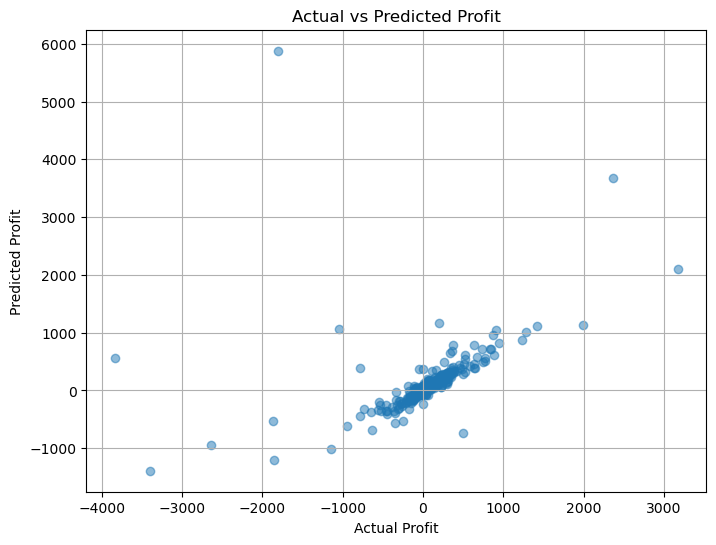

In [72]:
# 14. Plot Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Predicted Profit")
plt.grid(True)
plt.show()


In [73]:
# 15. Feature importance
feature_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nTop 15 Important Features:")
print(feature_importance_df.head(15))


Top 15 Important Features:
                  Feature  Importance
1                   Sales    0.732702
3                Discount    0.126249
580            State_Ohio    0.014442
257        City_Lancaster    0.014338
0             Postal Code    0.010667
606  Sub-Category_Binders    0.008740
2                Quantity    0.006822
6               Order Day    0.006414
600    Category_Furniture    0.006092
609  Sub-Category_Copiers    0.005241
5             Order Month    0.005041
588           State_Texas    0.004550
7           Shipping Days    0.003999
4              Order Year    0.003904
13      Segment_Corporate    0.003027


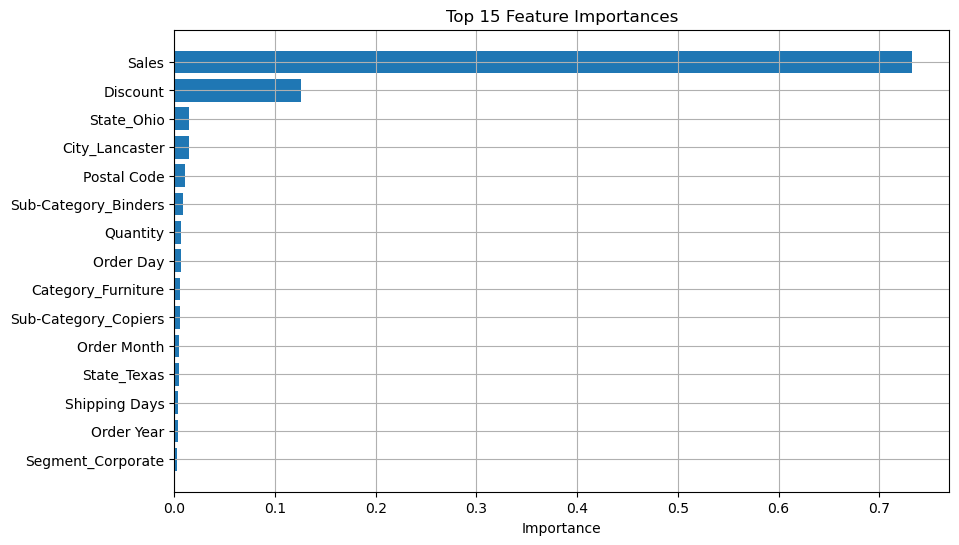

In [74]:
# 16. Plot top 15 features
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"][::-1], top_features["Importance"][::-1])
plt.xlabel("Importance")
plt.title("Top 15 Feature Importances")
plt.grid(True)
plt.show()

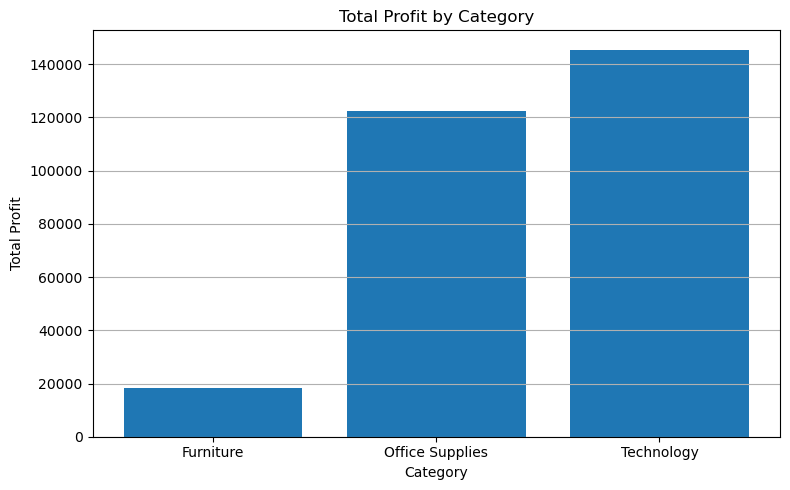

In [102]:

category_profit = df.groupby("Category")["Profit"].sum().sort_values()

plt.figure(figsize=(8, 5))
plt.bar(category_profit.index, category_profit.values)
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.title("Total Profit by Category")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()


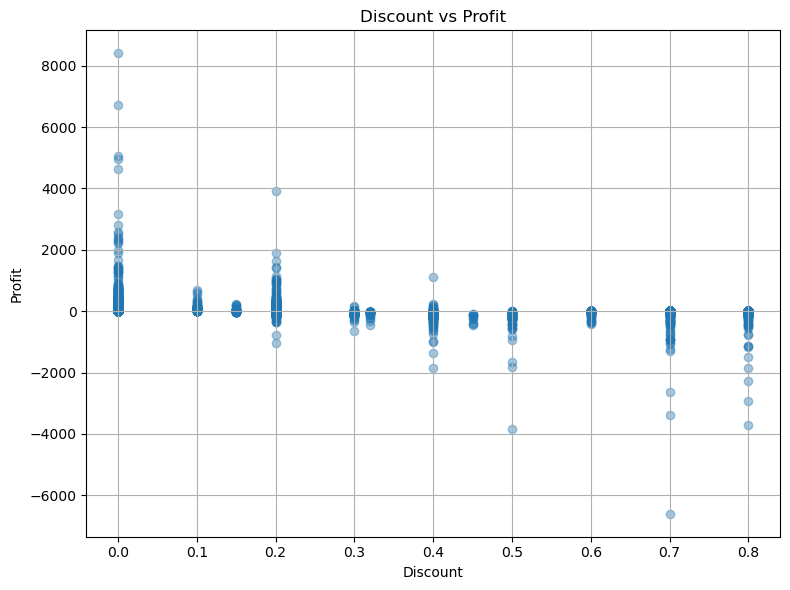

In [104]:

plt.figure(figsize=(8, 6))
plt.scatter(df["Discount"], df["Profit"], alpha=0.4)
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.title("Discount vs Profit")
plt.grid(True)
plt.tight_layout()
plt.show()


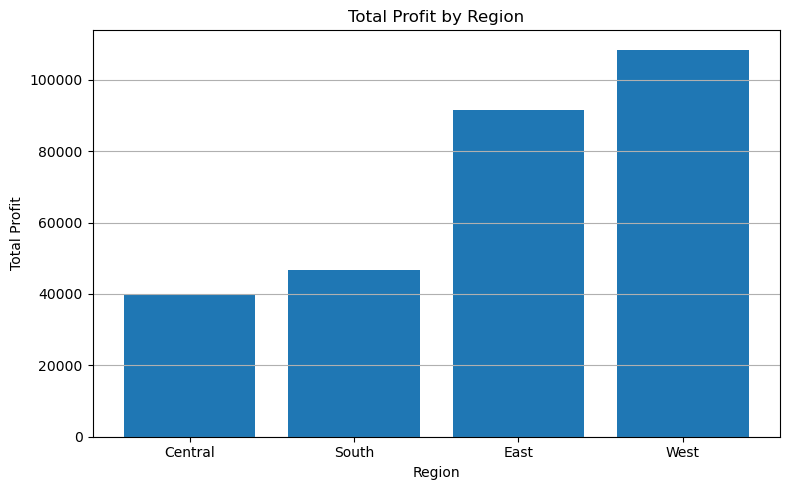

In [114]:

region_profit = df.groupby("Region")["Profit"].sum().sort_values()

plt.figure(figsize=(8, 5))
plt.bar(region_profit.index, region_profit.values)
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.title("Total Profit by Region")
plt.grid(True, axis="y")
plt.tight_layout()

plt.show()

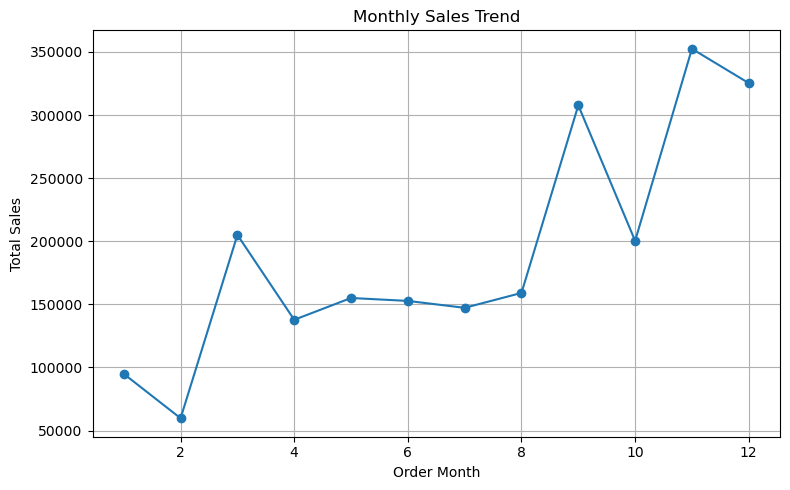

In [112]:

monthly_sales = df.groupby("Order Month")["Sales"].sum()

plt.figure(figsize=(8, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.xlabel("Order Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.grid(True)
plt.tight_layout()
plt.show()